In [1]:
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

# Set plot style
sns.set_theme(style="whitegrid")

# Load preprocessed dataset
df = pd.read_csv(r"D:\SML_project_folder\cleaned_supply_chain.csv")
print(f"Dataset Loaded: {df.shape[0]:,} rows, {df.shape[1]} columns")

Dataset Loaded: 180,519 rows, 43 columns


In [2]:
cluster_features = [
    "Days for shipping (real)",
    "Days for shipment (scheduled)",
    "Sales",
    "Order Item Quantity",
    "Order Item Discount Rate",
    "Order Profit Per Order",
    "Order Item Product Price",   # <-- changed from "Product Price"
    "Late_delivery_risk",
    "is_weekend",
    "order_hour",
]

X_cluster = df[cluster_features].copy()

# Standardize features (mean=0, std=1) before PCA and K-Means
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_cluster)
print("Feature matrix standardized successfully:", X_scaled.shape)

Feature matrix standardized successfully: (180519, 10)


PC1: 18.71% variance (Cumulative: 18.71%)
PC2: 15.19% variance (Cumulative: 33.90%)
PC3: 13.49% variance (Cumulative: 47.38%)
PC4: 11.84% variance (Cumulative: 59.23%)
PC5: 10.05% variance (Cumulative: 69.28%)
PC6: 10.01% variance (Cumulative: 79.29%)
PC7: 9.93% variance (Cumulative: 89.22%)
PC8: 9.05% variance (Cumulative: 98.27%)
PC9: 1.39% variance (Cumulative: 99.66%)
PC10: 0.34% variance (Cumulative: 100.00%)


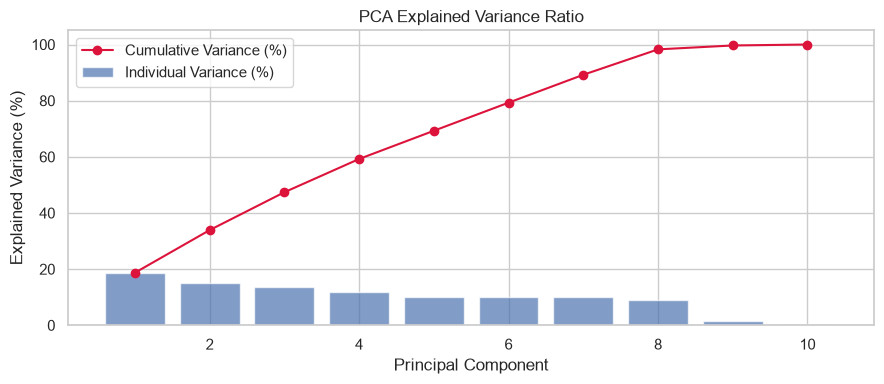

In [3]:
# Fit full PCA to inspect variance explained per component
pca_full = PCA(random_state=42)
pca_full.fit(X_scaled)

explained_var = pca_full.explained_variance_ratio_
cum_var = np.cumsum(explained_var)

for i, (ev, cv) in enumerate(zip(explained_var, cum_var), 1):
    print(f"PC{i}: {ev*100:.2f}% variance (Cumulative: {cv*100:.2f}%)")

# Plot Scree / Cumulative Variance Plot
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(
    range(1, len(explained_var) + 1),
    explained_var * 100,
    alpha=0.7,
    label="Individual Variance (%)",
)
ax.plot(
    range(1, len(cum_var) + 1),
    cum_var * 100,
    marker="o",
    color="crimson",
    label="Cumulative Variance (%)",
)
ax.set_xlabel("Principal Component")
ax.set_ylabel("Explained Variance (%)")
ax.set_title("PCA Explained Variance Ratio")
ax.legend()
plt.tight_layout()
plt.show()

# Reduce to 2D for K-Means & 2D visualization (captures 33.9% variance across 10 features cleanly)
pca_2d = PCA(n_components=2, random_state=42)
X_pca = pca_2d.fit_transform(X_scaled)

K = 2 | Inertia (WCSS) = 355,346.17
K = 3 | Inertia (WCSS) = 202,882.74
K = 4 | Inertia (WCSS) = 159,704.74
K = 5 | Inertia (WCSS) = 126,151.13
K = 6 | Inertia (WCSS) = 99,581.90
K = 7 | Inertia (WCSS) = 87,515.82
K = 8 | Inertia (WCSS) = 76,713.48


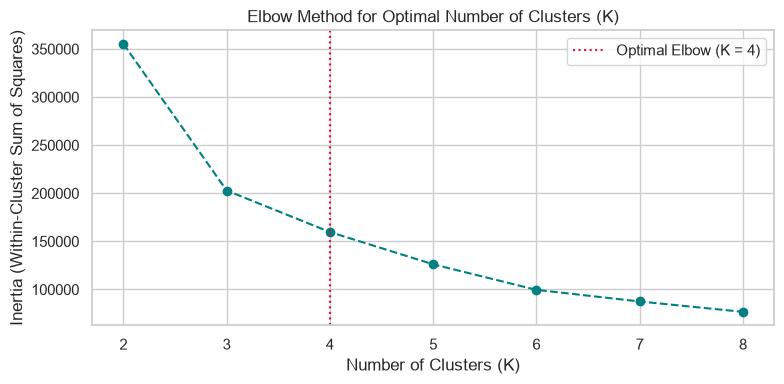

In [4]:
inertias = []
K_range = range(2, 9)

for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_pca)
    inertias.append(km.inertia_)
    print(f"K = {k} | Inertia (WCSS) = {km.inertia_:,.2f}")

# Plot Elbow Curve
plt.figure(figsize=(8, 4))
plt.plot(K_range, inertias, marker="o", linestyle="--", color="teal")
plt.axvline(
    x=4, color="crimson", linestyle=":", label="Optimal Elbow (K = 4)"
)
plt.title("Elbow Method for Optimal Number of Clusters (K)")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia (Within-Cluster Sum of Squares)")
plt.legend()
plt.tight_layout()
plt.show()

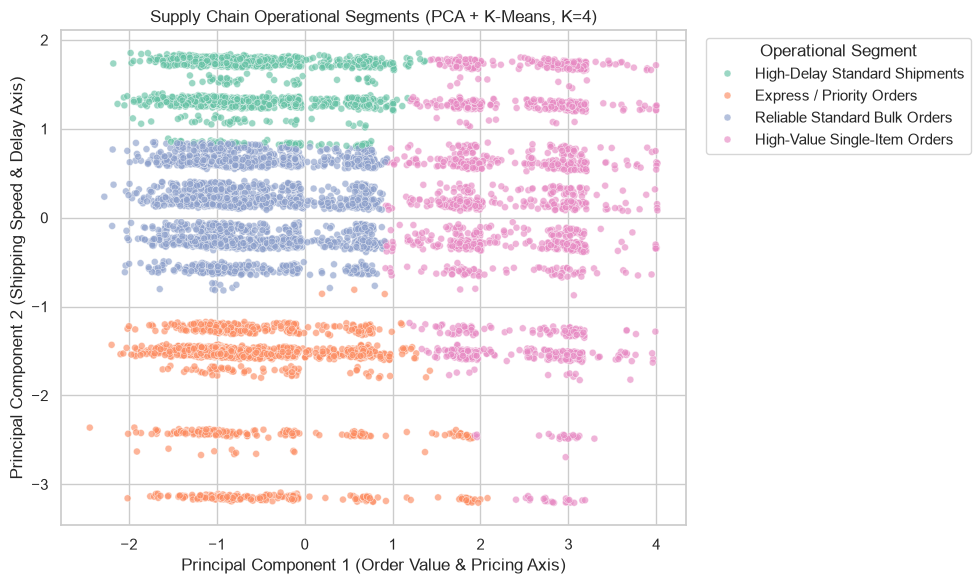

In [5]:
optimal_k = 4
kmeans = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
df["Cluster"] = kmeans.fit_predict(X_pca)
df["PCA1"] = X_pca[:, 0]
df["PCA2"] = X_pca[:, 1]

# Map human-readable business names to clusters
cluster_labels = {
    0: "High-Delay Standard Shipments",
    1: "Express / Priority Orders",
    2: "High-Value Single-Item Orders",
    3: "Reliable Standard Bulk Orders",
}
df["Cluster_Name"] = df["Cluster"].map(cluster_labels)

# Scatter plot on a 10,000-row sample for crisp rendering
sample_df = df.sample(n=10000, random_state=42)
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=sample_df,
    x="PCA1",
    y="PCA2",
    hue="Cluster_Name",
    palette="Set2",
    alpha=0.65,
    s=25,
)
plt.title("Supply Chain Operational Segments (PCA + K-Means, K=4)")
plt.xlabel("Principal Component 1 (Order Value & Pricing Axis)")
plt.ylabel("Principal Component 2 (Shipping Speed & Delay Axis)")
plt.legend(title="Operational Segment", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

In [6]:
# Summary table of numerical averages by cluster
cluster_profile = df.groupby(["Cluster", "Cluster_Name"])[cluster_features].mean().round(2)
cluster_profile["Order_Count"] = df.groupby("Cluster").size().values
cluster_profile["Share (%)"] = (cluster_profile["Order_Count"] / len(df) * 100).round(1)
print(cluster_profile.T)

# Save artifacts for Streamlit app.py
joblib.dump(scaler, r"D:\SML_project_folder\cluster_scaler.joblib")
joblib.dump(pca_2d, r"D:\SML_project_folder\pca_2d.joblib")
joblib.dump(kmeans, r"D:\SML_project_folder\kmeans_model.joblib")
joblib.dump(cluster_features, r"D:\SML_project_folder\cluster_features.joblib")
joblib.dump(cluster_labels, r"D:\SML_project_folder\cluster_labels.joblib")

# Save dataset with cluster assignments for fast dashboard loading
df.to_csv(r"D:\SML_project_folder\clustered_supply_chain.csv", index=False)
print("All clustering models and clustered dataset saved successfully!")

Cluster                                                   0  \
Cluster_Name                  High-Delay Standard Shipments   
Days for shipping (real)                               5.53   
Days for shipment (scheduled)                          3.93   
Sales                                                163.09   
Order Item Quantity                                    2.37   
Order Item Discount Rate                               0.10   
Order Profit Per Order                                13.95   
Order Item Product Price                              87.10   
Late_delivery_risk                                     0.96   
is_weekend                                             0.28   
order_hour                                            11.79   
Order_Count                                        35955.00   
Share (%)                                             19.90   

Cluster                                               1  \
Cluster_Name                  Express / Priority Orders   